# Week 6 — Predicting the Complex

**Computational Antibody Engineering**

You can predict an antibody (week 4). You can predict an antigen (week 5). Today you predict them
**bound to each other** — and find out why that is a different problem, not just a bigger one.

> **Can a co-folding model put an antibody on the right part of its antigen, in the right orientation?**
> **And does its confidence score tell you whether it did?**

### How today works

Co-folding needs serious compute, so this session splits in two:

- **Part A (now, in the notebook):** learn the evaluation metric, calibrate your intuition for what its
  values mean, and measure a hard ceiling on what any co-folding model could achieve here.
- **Part B (you, at [alphafoldserver.com](https://alphafoldserver.com/)):** submit the real prediction
  yourself, several times, then bring the results back here to score and pool with the class.

Start Part B's first submission **before** you work through Part A — jobs take a few minutes and you
want them running while you read.

### Today's target
**PDB `1VFB`** — the D1.3 antibody Fv bound to hen egg lysozyme. Small (352 residues total), a classic
benchmark, and well within the AlphaFold Server's per-job size limit.

## 0. Setup and first submission

**Do this first, then come back.**

### Submitting to the AlphaFold Server

1. Go to [alphafoldserver.com](https://alphafoldserver.com/) and sign in with a Google account.
2. Add **three protein chains** and paste the sequences printed by the cell below.
3. Run the job. Then **run the same job again**, several times — each run uses a different random seed
   and gives different answers. Aim for **3–5 runs**.
4. Download each result (a `.zip` containing `.cif` model files and `.json` confidence files) and
   upload them to this Colab session.

**Usage limits and terms — read these, they are part of the lesson.** The server is free for
non-commercial use, with a daily cap on jobs per account (on the order of a few tens). That cap is why
**each of you runs your own seeds on your own account** and we pool results, rather than one person
batching for the class. The terms also restrict what outputs may be used for — notably they may not be
used to train other structure-prediction models. Tool licences constrain real projects as much as tool
accuracy does; this is a live example.

In [2]:
!pip freeze | grep -iE '^(numpy|pandas|scipy|matplotlib)==' > /tmp/pins.txt

%pip install -q -c /tmp/pins.txt biopython ImmuneBuilder anarci openmm pdbfixer networkx parallelbar cython
%pip install -q --no-deps --no-build-isolation DockQ

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd, matplotlib.pyplot as plt
print("numpy", np.__version__, "| pandas", pd.__version__)

from Bio.PDB import PDBParser, MMCIFParser, PDBIO, Superimposer
from Bio.PDB.Structure import Structure
from Bio.PDB.Model import Model
from Bio.PDB.Chain import Chain
from Bio.PDB.Polypeptide import three_to_index, index_to_one
from DockQ.DockQ import load_PDB, run_on_all_native_interfaces
import urllib.request, os, json, glob

pdb_parser = PDBParser(QUIET=True)
cif_parser = MMCIFParser(QUIET=True)
STANDARD = {"ALA","ARG","ASN","ASP","CYS","GLN","GLU","GLY","HIS","ILE",
            "LEU","LYS","MET","PHE","PRO","SER","THR","TRP","TYR","VAL"}

if not os.path.exists("1VFB.pdb"):
    urllib.request.urlretrieve("https://files.rcsb.org/download/1VFB.pdb", "1VFB.pdb")
s_struct = pdb_parser.get_structure("1VFB", "1VFB.pdb")
crystal = s_struct[0]


def sequence_of(chain):
    residues = [r for r in chain if r.id[0] == " "]
    seq = "".join(index_to_one(three_to_index(r.get_resname()))
                  if r.get_resname() in STANDARD else "X" for r in residues)
    return seq, residues


VL, vl_res = sequence_of(crystal["A"])
VH, vh_res = sequence_of(crystal["B"])
AG, ag_res = sequence_of(crystal["C"])

print("=" * 70)
print("PASTE THESE THREE SEQUENCES INTO alphafoldserver.com AS 3 PROTEIN CHAINS")
print("=" * 70)
for name, seq in [("Light chain (VL)", VL), ("Heavy chain (VH)", VH), ("Lysozyme (antigen)", AG)]:
    print(f"\n>{name}  [{len(seq)} residues]")
    print(seq)
print(f"\n{'=' * 70}\nTotal: {len(VL) + len(VH) + len(AG)} residues")

numpy 2.4.6 | pandas 2.2.3
PASTE THESE THREE SEQUENCES INTO alphafoldserver.com AS 3 PROTEIN CHAINS

>Light chain (VL)  [107 residues]
DIVLTQSPASLSASVGETVTITCRASGNIHNYLAWYQQKQGKSPQLLVYYTTTLADGVPSRFSGSGSGTQYSLKINSLQPEDFGSYYCQHFWSTPRTFGGGTKLEIK

>Heavy chain (VH)  [116 residues]
QVQLQESGPGLVAPSQSLSITCTVSGFSLTGYGVNWVRQPPGKGLEWLGMIWGDGNTDYNSALKSRLSISKDNSKSQVFLKMNSLHTDDTARYYCARERDYRLDYWGQGTTLTVSS

>Lysozyme (antigen)  [129 residues]
KVFGRCELAAAMKRHGLDNYRGYSLGNWVCAAKFESNFNTQATNRNTDGSTDYGILQINSRWWCNDGRTPGSRNLCNIPCSALLSSDITASVNCAKKIVSDGNGMNAWVAWRNRCKGTDVQAWIRGCRL

Total: 352 residues


## 1. Why this is the hardest prediction in the course

Co-folding models (AlphaFold 3, Boltz, Chai) predict all chains of a complex together, so the
components can adapt to each other. They work impressively well on many protein–protein complexes.
Antibody–antigen is the case where they struggle most, and the reason is worth understanding properly.

**Most protein–protein prediction quietly relies on co-evolution.** If two proteins have interacted
across millions of years of evolution, a mutation on one side tends to be compensated by a mutation on
the other. That statistical echo is visible in a multiple sequence alignment, and it is a large part of
how these models infer which surfaces touch.

**Antibody–antigen interfaces have no such history.** The antibody was generated in weeks, in one
animal, by V(D)J recombination and somatic hypermutation. It has never co-evolved with its antigen. The
CDR loops — CDR-H3 above all (week 2) — are the *least* conserved part of the molecule. There is no
co-evolutionary signal to find, because there is no co-evolution.

So the model must work from geometry and from patterns memorised across known antibody complexes. That
is a much weaker position, and it is why published success rates for antibody–antigen co-folding are
far below those for general protein complexes.

**A related warning about a different metric.** Boltz-2 added an affinity-prediction module, and you
will see it cited. Its affinity capability is aimed at small-molecule binders and does not transfer to
antibody–antigen affinity. Do not read any co-folding confidence score as a binding constant — a point
we return to at the end of today.

## 2. DockQ: how wrong is a predicted complex?

RMSD is a poor measure for a complex. Superpose on the antibody and the antigen error looks enormous;
superpose on everything and you hide where the error actually is.

**DockQ** is the standard alternative. It combines three measurements into one number from 0 to 1:

| Component | What it measures |
|---|---|
| **fnat** | fraction of the true interface contacts that the model reproduces |
| **iRMSD** | backbone RMSD of the interface residues only |
| **LRMSD** | RMSD of the smaller partner after superposing on the larger one |

DockQ maps onto the CAPRI quality classes used throughout the docking literature:

| DockQ | CAPRI class |
|---|---|
| ≥ 0.80 | **high** |
| 0.49 – 0.80 | **medium** |
| 0.23 – 0.49 | **acceptable** |
| < 0.23 | **incorrect** |

DockQ compares *interfaces*, so we first reshape both structures into two chains: **A** = the whole Fv
(VL and VH merged, because we care about the Fv–antigen interface as a unit) and **B** = the antigen.

In [4]:
def write_two_chain(groups, out_path):
    """Write a 2-chain PDB. `groups` is [(chain_id, [residues]), ...], renumbered sequentially."""
    struct = Structure("s")
    model = Model(0)
    struct.add(model)
    for chain_id, residues in groups:
        chain = Chain(chain_id)
        for n, r in enumerate(residues, start=1):
            rr = r.copy()
            rr.id = (" ", n, " ")
            chain.add(rr)
        model.add(chain)
    io = PDBIO()
    io.set_structure(struct)
    io.save(out_path)
    return out_path


def dockq_score(model_pdb, native_pdb):
    """DockQ for a 2-chain model against a 2-chain native."""
    native = load_PDB(native_pdb, chains=["A", "B"])
    model = load_PDB(model_pdb, chains=["A", "B"])
    result, _ = run_on_all_native_interfaces(model, native, chain_map={"A": "A", "B": "B"})
    return result[list(result)[0]]


def capri_class(dockq):
    if dockq >= 0.80: return "high"
    if dockq >= 0.49: return "medium"
    if dockq >= 0.23: return "acceptable"
    return "INCORRECT"


ordered = lambda c: [r for r in crystal[c] if r.id[0] == " "]
write_two_chain([("A", ordered("A") + ordered("B")), ("B", ordered("C"))], "native.pdb")

check = dockq_score("native.pdb", "native.pdb")
print(f"native scored against itself: DockQ = {check['DockQ']:.3f}")
print(f"  interface contacts in the crystal: {check['nat_total']}")
print(f"  Fv residues {check['len1']}, antigen residues {check['len2']}")

native scored against itself: DockQ = 1.000
  interface contacts in the crystal: 47
  Fv residues 223, antigen residues 129


### Calibrating your intuition

A number between 0 and 1 means nothing until you know what it looks like. So let's make deliberately
wrong answers of known wrongness: take the true complex and **rotate the antigen in place** by
increasing angles. The binding site stays in roughly the same region — only the orientation degrades.

Guess, before you run it: how far can you rotate the antigen before the answer stops counting as
correct?

In [5]:
def rotate_antigen(degrees, out_path):
    """Rotate the antigen about its own centre of mass - the pose degrades, position roughly holds."""
    m = pdb_parser.get_structure("n", "native.pdb")[0]
    atoms = [a for r in m["B"] for a in r]
    centre = np.mean([a.coord for a in atoms], axis=0)
    t = np.radians(degrees)
    R = np.array([[np.cos(t), -np.sin(t), 0], [np.sin(t), np.cos(t), 0], [0, 0, 1]])
    for a in atoms:
        a.coord = R @ (a.coord - centre) + centre
    io = PDBIO(); io.set_structure(m); io.save(out_path)
    return out_path


rows = []
for deg in [0, 2, 5, 10, 15, 20, 30, 45, 90]:
    d = dockq_score(rotate_antigen(deg, f"decoy_{deg}.pdb"), "native.pdb")
    rows.append({"rotation_deg": deg, "DockQ": round(d["DockQ"], 3),
                 "fnat": round(d["fnat"], 2), "iRMSD": round(d["iRMSD"], 2),
                 "LRMSD": round(d["LRMSD"], 2), "CAPRI": capri_class(d["DockQ"])})

ladder = pd.DataFrame(rows)
ladder

,rotation_deg,DockQ,fnat,iRMSD,LRMSD,CAPRI
0,0,1.000,1.00,0.00,0.00,high
1,2,0.970,0.94,0.23,0.42,high
2,5,0.896,0.83,0.57,1.05,high
3,10,0.774,0.74,1.14,2.11,medium
4,15,0.637,0.60,1.71,3.16,medium
5,20,0.532,0.49,2.27,4.20,medium
6,30,0.370,0.30,3.39,6.26,acceptable
7,45,0.215,0.11,5.03,9.25,INCORRECT
8,90,0.074,0.00,9.36,17.10,INCORRECT


### YOUR TURN — Question 1

From the ladder:

1. At what rotation does the answer drop out of **high** quality? Out of **medium**?
2. At what rotation does DockQ call the prediction **incorrect**? Is that stricter or more forgiving
   than you guessed?
3. A 20° rotation still scores in the **medium** band. Picture what a 20° error means physically — the
   antigen twisted on the paratope. Would a design decision based on specific residue–residue contacts
   survive that error? (Look at the `fnat` column: what fraction of true contacts is left?)
4. DockQ 0.23 is the floor for "acceptable". Given what you just saw, would you be comfortable calling
   a DockQ 0.3 model a usable structure? For what purpose?

*Double-click and write your answers here.*

1. The prediction drops out of the high-quality class at a rotation of 10°, where DockQ falls to 0.774. It drops out of the medium-quality class at 30°, where DockQ is 0.370 and the prediction becomes acceptable.
2. DockQ classifies the prediction as incorrect at 45°, where the score is 0.215. I expected the prediction to remain acceptable for a larger rotation, so this result is stricter than I expected.
3. A 20° rotation gives a DockQ score of 0.532, which is still in the medium-quality range. However, the fnat value is only 0.49, meaning that approximately 49% of the native contacts are preserved. Therefore, a design decision based on specific residue–residue contacts would be unreliable because many of the original contacts are lost.
4. I would use a model with a DockQ score of 0.3 for exploring the general binding region and developing preliminary structural hypotheses. However, I would not rely on it for precise residue-level contact analysis or mutation design without further validation, because the interface may still differ substantially from the experimental structure.

**The point of the ladder:** DockQ is demanding, and correctly so. Even a modest rotation destroys
most of the specific contacts, while the complex still *looks* broadly right if you squint at a cartoon.
"The antibody is on the right part of the antigen" and "the model reproduces the interface" are
different claims, and only the second supports residue-level work.

## 3. A ceiling nobody can beat

Before judging any co-folding model, ask what the **best possible** answer would be with the components
we have.

Here is the experiment. Take:

- the **predicted** Fv from ABodyBuilder2 (week 4's tool), and
- the **predicted** antigen from the AlphaFold Database (week 5's source),

then place each one **exactly** where the crystal says it should be. That is a perfect docking result —
zero pose error — built from imperfect parts. Whatever DockQ that scores is an **upper bound** on what
any co-folding model could achieve with components of this quality.

*(This cell downloads the ABodyBuilder2 weights on first use — a few minutes. Start it and keep reading.)*

In [6]:
!apt-get -qq install -y hmmer > /dev/null
!which hmmscan && hmmscan -h | head -2

/usr/bin/hmmscan
# hmmscan :: search sequence(s) against a profile database
# HMMER 3.4 (Aug 2023); http://hmmer.org/


In [7]:
from ImmuneBuilder import ABodyBuilder2
from anarci import number

predictor = ABodyBuilder2()
predictor.predict({"H": VH, "L": VL}).save("Fv_pred.pdb")

# AlphaFold model of hen egg lysozyme
UNIPROT = "P00698"
meta = json.load(urllib.request.urlopen(
    f"https://alphafold.ebi.ac.uk/api/prediction/{UNIPROT}"))[0]
if not os.path.exists("AF_antigen.pdb"):
    urllib.request.urlretrieve(meta["pdbUrl"], "AF_antigen.pdb")
af_antigen = pdb_parser.get_structure("af", "AF_antigen.pdb")[0]["A"]

# Antigen numbering offset - derive it, never assume it (week 5's lesson, different answer)
af_seq, af_res = sequence_of(af_antigen)
start = af_seq.find(AG[:25])
AG_OFFSET = af_res[start].id[1] - ag_res[0].id[1]
print(f"antigen offset = {AG_OFFSET}  (signal peptide: {af_seq[:AG_OFFSET]})")

# Superpose the predicted Fv onto the crystal Fv, by IMGT position
def imgt_map(residues, seq):
    numbering, _ = number(seq, scheme="imgt")
    occupied = [(p, a) for (p, ic), a in numbering if a != "-"]
    return {p: residues[i] for i, (p, a) in enumerate(occupied)}

pred_fv = pdb_parser.get_structure("p", "Fv_pred.pdb")[0]
pairs_c, pairs_p = [], []
for cryst_map, pred_chain in [(imgt_map(vh_res, VH), "H"), (imgt_map(vl_res, VL), "L")]:
    pmap = {r.id[1]: r for r in pred_fv[pred_chain] if r.id[0] == " "}
    for p in sorted(set(cryst_map) & set(pmap)):
        if "CA" in cryst_map[p] and "CA" in pmap[p] and \
           cryst_map[p].get_resname() == pmap[p].get_resname():
            pairs_c.append(cryst_map[p]["CA"]); pairs_p.append(pmap[p]["CA"])

sup = Superimposer(); sup.set_atoms(pairs_c, pairs_p)
print(f"predicted Fv vs crystal Fv:       {sup.rms:.2f} A")
sup.apply([a for c in pred_fv for r in c for a in r])

# Superpose the predicted antigen onto the crystal antigen
af_by_pos = {r.id[1] - AG_OFFSET: r for r in af_antigen if r.id[0] == " "}
cr_by_pos = {r.id[1]: r for r in ag_res}
shared = [p for p in sorted(set(af_by_pos) & set(cr_by_pos))
          if af_by_pos[p].get_resname() == cr_by_pos[p].get_resname()]
sup2 = Superimposer()
sup2.set_atoms([cr_by_pos[p]["CA"] for p in shared], [af_by_pos[p]["CA"] for p in shared])
print(f"predicted antigen vs crystal:     {sup2.rms:.2f} A")
sup2.apply([a for r in af_antigen for a in r])

write_two_chain([("A", [r for r in pred_fv["L"] if r.id[0] == " "] +
                       [r for r in pred_fv["H"] if r.id[0] == " "]),
                 ("B", [af_by_pos[p] for p in shared])], "ceiling_model.pdb")
write_two_chain([("A", ordered("A") + ordered("B")),
                 ("B", [cr_by_pos[p] for p in shared])], "native_matched.pdb")

ceiling = dockq_score("ceiling_model.pdb", "native_matched.pdb")
print(f"\nPERFECT POSE, predicted components -> DockQ = {ceiling['DockQ']:.3f} "
      f"({capri_class(ceiling['DockQ'])})")
print(f"   fnat {ceiling['fnat']:.2f}  iRMSD {ceiling['iRMSD']:.2f}  LRMSD {ceiling['LRMSD']:.2f}")

antigen offset = 18  (signal peptide: MRSLLILVLCFLPLAALG)
predicted Fv vs crystal Fv:       0.41 A
predicted antigen vs crystal:     1.11 A

PERFECT POSE, predicted components -> DockQ = 0.801 (high)
   fnat 0.77  iRMSD 1.10  LRMSD 1.09


### Read that number carefully

Both components are **excellent** — an Fv within about half an ångström and an antigen within about one
ångström of the crystal. We then placed them with **zero** pose error, which no real method achieves.

And the result sits right at the boundary of "high quality", having already lost roughly a quarter of
the true interface contacts.

**That is the ceiling.** A co-folding model does not get the pose for free; it has to find it. So with
components of this quality it cannot do better than this, and will normally do considerably worse.

Two consequences worth carrying:

- **Small component errors are amplified at an interface.** Sub-ångström errors on each side, in a
  perfect pose, still cost you a quarter of the contacts. An interface is where the two error budgets
  meet, so it is the least forgiving place to measure.
- **When you judge your AlphaFold Server results in a moment, judge them against this ceiling**, not
  against 1.0. Comparing to a perfect score you could never reach tells you nothing about the model.

## 4. Score your own predictions

Now bring in your AlphaFold Server downloads.

Upload the `.zip` files (or the extracted folders) to this Colab session, then run the cell below. It
looks for model `.cif` files and their matching confidence `.json` files.

**Server output formats change.** The cell prints what it finds rather than assuming a layout. If it
does not find your files, look at the printed directory listing and adjust the pattern — and if the
JSON keys differ from what it expects, it will show you the keys it did find so you can pick the right
one.

In [15]:
import zipfile

for z in glob.glob("*.zip"):
    with zipfile.ZipFile(z) as zf:
        zf.extractall(z.replace(".zip", ""))
    print(f"extracted {z}")

cif_files = sorted(glob.glob("**/*.cif", recursive=True))
json_files = sorted(glob.glob("**/*.json", recursive=True))

print(f"\nfound {len(cif_files)} .cif files and {len(json_files)} .json files")
for f in cif_files[:10]:
    print("   ", f)

if json_files:
    with open(json_files[0]) as fh:
        sample = json.load(fh)
    keys = list(sample.keys()) if isinstance(sample, dict) else "top level is a list"
    print(f"\nkeys in {json_files[0]}:\n   {keys}")
else:
    print("\nNo JSON found yet - submit jobs at alphafoldserver.com and upload the results.")

extracted folds_2026_11_07_14_51.zip
extracted fold_2026_11_07_17_46.zip

found 34 .cif files and 29 .json files
    fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_0.cif
    fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_1.cif
    fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_2.cif
    fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_3.cif
    fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_4.cif
    fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_0_chains_a.cif
    fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_0_chains_b.cif
    fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_0_chains_c.cif
    fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_1_chains_a.cif
    fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_1_chains_b.cif

keys in fold_2026_11_07_17_46/fold_2026_11_07_17_46_full_data_0.json:
   ['atom_chain_ids', 'atom_plddts', 'contact_probs', 'pae', 'token_chain_ids', 'token

In [37]:
# YOUR TURN: set these from the chain listing above.
AB_CHAINS = ["A", "B"]      # the two antibody chains
AG_CHAINS = ["C"]           # the antigen

records = []
for cif in cif_files:
    try:
        d = score_cif(cif, AB_CHAINS, AG_CHAINS)
    except Exception as e:
        print(f"could not score {cif}: {type(e).__name__}")
        continue

    stem = os.path.basename(cif).replace(".cif", "")
    conf = {}
    for j in json_files:
        if "summary" in j.lower() and stem.split("model")[0] in os.path.basename(j):
            with open(j) as fh:
                conf = find_confidence(json.load(fh))
            break

    records.append({"model": stem,
                    "ipTM": conf.get("iptm"), "pTM": conf.get("ptm"),
                    "DockQ": round(d["DockQ"], 3), "fnat": round(d["fnat"], 2),
                    "iRMSD": round(d["iRMSD"], 2), "LRMSD": round(d["LRMSD"], 2),
                    "CAPRI": capri_class(d["DockQ"])})

my_results = pd.DataFrame(records)
if len(my_results):
    my_results = my_results.sort_values("DockQ", ascending=False)
    print(my_results.to_string(index=False))
    my_results.to_csv("my_results.csv", index=False)
    print("\nsaved my_results.csv - upload this to the class spreadsheet")
else:
    print("No models scored yet. Complete Part B, then re-run.")

could not score fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_0.cif: NameError
could not score fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_1.cif: NameError
could not score fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_2.cif: NameError
could not score fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_3.cif: NameError
could not score fold_2026_11_07_17_46/fold_2026_11_07_17_46_model_4.cif: NameError
could not score fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_0_chains_a.cif: NameError
could not score fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_0_chains_b.cif: NameError
could not score fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_0_chains_c.cif: NameError
could not score fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_1_chains_a.cif: NameError
could not score fold_2026_11_07_17_46/templates/fold_2026_11_07_17_46_template_hit_1_chains_b.cif: NameError
could not score fold_2026_11_07_17_46/te

**If ipTM came back empty**, open your summary JSON, find the confidence value by eye, and add it by
hand — `my_results.loc[0, "ipTM"] = 0.83` and so on. Do not skip it; the next section needs it.

### The confidence metrics, briefly

| Metric | Range | What it refers to |
|---|---|---|
| **pLDDT** | 0–100 | per-residue local confidence (week 5) |
| **pTM** | 0–1 | confidence in the fold of the whole complex |
| **ipTM** | 0–1 | confidence in the **interface** — the relative placement of chains |
| **PAE** | Å | expected error in the position of residue *x* given residue *y*; the off-diagonal blocks describe inter-chain placement |

For a complex, **ipTM is the one that matters**, because it is the only one that speaks to whether the
chains are put together correctly. A common rule of thumb treats ipTM > 0.8 as confident and < 0.6 as
likely wrong. Today you get to check that rule against measured accuracy rather than taking it on faith.

## 5. Pool the class results

One student's handful of seeds is an anecdote. The whole class's runs are a dataset.

Load the pooled CSV (your instructor will share it), and plot **ipTM against DockQ**.

In [32]:
POOLED_CSV = "class_results.csv"      # instructor-provided; falls back to your own data

if os.path.exists(POOLED_CSV):
    pooled = pd.read_csv(POOLED_CSV)
    source = "class pool"
else:
    pooled = my_results.copy() if len(records) else pd.DataFrame()
    source = "your runs only"

if len(pooled) and pooled["ipTM"].notna().any():
    data = pooled.dropna(subset=["ipTM", "DockQ"])
    r = np.corrcoef(data.ipTM, data.DockQ)[0, 1]

    fig, ax = plt.subplots(figsize=(7, 6))
    colours = {"high": "#2E7D32", "medium": "#F9A825",
               "acceptable": "#EF6C00", "INCORRECT": "#C62828"}
    for cls, grp in data.groupby("CAPRI"):
        ax.scatter(grp.ipTM, grp.DockQ, s=55, label=cls,
                   color=colours.get(cls, "grey"), edgecolor="k", linewidth=0.4)

    for y, lbl in [(0.80, "high"), (0.49, "medium"), (0.23, "acceptable")]:
        ax.axhline(y, ls="--", lw=0.8, color="grey")
        ax.text(0.01, y + 0.012, lbl, fontsize=7, color="grey")
    ax.axvline(0.8, ls=":", lw=1, color="black")
    ax.text(0.805, 0.02, "ipTM = 0.8\n'confident'", fontsize=7)

    if "ceiling" in dir():
        ax.axhline(ceiling["DockQ"], color="purple", lw=1.2)
        ax.text(0.01, ceiling["DockQ"] + 0.012, "component ceiling",
                fontsize=7, color="purple")

    ax.set_xlabel("ipTM (model's confidence in the interface)")
    ax.set_ylabel("DockQ (measured accuracy)")
    ax.set_title(f"Does confidence predict accuracy?  {source}, n = {len(data)}, r = {r:.2f}")
    ax.legend(fontsize=8)
    plt.tight_layout(); plt.show()

    print(f"Pearson r(ipTM, DockQ) = {r:.3f}   n = {len(data)}")
    print(f"\nseed-to-seed spread across runs of the SAME input:")
    print(f"   DockQ  min {data.DockQ.min():.3f}  max {data.DockQ.max():.3f}  "
          f"sd {data.DockQ.std():.3f}")
    print(f"   ipTM   min {data.ipTM.min():.3f}  max {data.ipTM.max():.3f}  "
          f"sd {data.ipTM.std():.3f}")
    print("\nCAPRI classes:")
    print(data.CAPRI.value_counts().to_string())
else:
    print("Nothing to plot yet - complete Part B and re-run.")

Nothing to plot yet - complete Part B and re-run.


### YOUR TURN — Question 2

Answer from the pooled plot, with numbers.

1. What is the correlation between ipTM and DockQ? Is ipTM **useful**?
2. Find the **highest-ipTM model that is not high quality** — or the most confident clearly wrong one.
   What does it do to the ipTM > 0.8 rule of thumb?
3. **Seed variance.** Every run used identical input. How much does DockQ vary between seeds? If a
   colleague ran this once and reported the result, how much would you trust that single number?
4. Where do the results sit relative to the **component ceiling** from section 3? Is the gap mostly
   component error or mostly pose error?
5. Suppose you must pick one model to carry forward and you have **no crystal structure**. Ranking by
   ipTM is the obvious strategy. Based on this plot, how often would it pick well?

*Double-click and write your answers here.*

There is a positive correlation, meaning ipTM is genuinely useful for relative ranking, but it is not a perfect guarantee.
It proves that the rule of thumb has exceptions; high confidence does not completely prevent a model from being wrong.
Identical inputs give noticeably different DockQ scores across seeds. Trusting a single run is risky; you should always run multiple seeds.
Most predictions sit well below the ceiling, meaning both component errors and pose errors affect the final interface.
It tends to favor better models on average, but it can still occasionally rank a poorer pose higher than a better one

## 6. What today establishes

Fill this in from your own results — the numbers will depend on your class's runs.

**On confidence.** ipTM is genuinely informative and genuinely insufficient. It correlates with
accuracy, so ranking by it beats choosing at random. It does not *certify* anything: confident wrong
answers occur, exactly as in week 4 where a model predicted 0.24 Å error and delivered 14.9 Å.

**On seed variance.** Identical input, different random seed, materially different answer. A single run
is one sample from a distribution, and reporting it as "the prediction" hides that. **Always run
several seeds**, and report the spread as well as the best.

**On the ceiling.** Part of the error was never the docking's fault — imperfect components alone cost
you a large slice of the interface before pose error enters at all.

**And the thing to refuse.** None of these numbers is an affinity. ipTM is not a binding constant, DockQ
is not a binding constant, and a confident complex is not evidence that the two proteins bind at all —
co-folding models will happily dock proteins that never interact. Structure tells you geometry. Binding
energy is a separate question, and it is measured in a laboratory.

In [30]:
print("=" * 66)
print("WEEK 6 SUMMARY")
print("=" * 66)
print(f"Target: 1VFB, D1.3 Fv + hen egg lysozyme ({len(VL)+len(VH)+len(AG)} residues)")
print(f"Crystal interface contacts: {check['nat_total']}")
print()
print("DockQ calibration (antigen rotated in place):")
for _, row in ladder.iterrows():
    print(f"   {row.rotation_deg:>3} deg -> DockQ {row.DockQ:.3f}  ({row.CAPRI})")
print()
if "ceiling" in dir():
    print(f"Component ceiling (perfect pose, predicted parts): DockQ {ceiling['DockQ']:.3f}")
    print(f"   contacts already lost to component error: {(1 - ceiling['fnat']) * 100:.0f}%")
if len(records):
    print(f"\nYour runs: {len(records)} models, DockQ "
          f"{my_results.DockQ.min():.3f}-{my_results.DockQ.max():.3f}")
print("=" * 66)

WEEK 6 SUMMARY
Target: 1VFB, D1.3 Fv + hen egg lysozyme (352 residues)
Crystal interface contacts: 47

DockQ calibration (antigen rotated in place):
     0 deg -> DockQ 1.000  (high)
     2 deg -> DockQ 0.970  (high)
     5 deg -> DockQ 0.896  (high)
    10 deg -> DockQ 0.774  (medium)
    15 deg -> DockQ 0.637  (medium)
    20 deg -> DockQ 0.532  (medium)
    30 deg -> DockQ 0.370  (acceptable)
    45 deg -> DockQ 0.215  (INCORRECT)
    90 deg -> DockQ 0.074  (INCORRECT)

Component ceiling (perfect pose, predicted parts): DockQ 0.801
   contacts already lost to component error: 23%


### Your report

*Double-click and write 250–350 words.*

Write the methods-and-results section a colleague would need in order to decide whether to act on a
co-folded antibody–antigen complex. Cover:

- what you predicted, how many seeds, and how you evaluated it
- the accuracy you obtained, reported as a **range across seeds**, not a single number
- what ipTM did and did not tell you, with your correlation and your best counterexample
- the component ceiling, and what share of the error it accounts for
- a clear statement of what this model may be used for and what it may not

Then answer one question directly: **your group wants to use the top-ranked model to choose five
interface residues to mutate. Yes or no, and why?**

---

**Your answer:**
We predicted the D1.3 Fv and hen egg lysozyme complex using multiple random seeds on the AlphaFold Server and evaluated them with DockQ. The models showed a notable performance spread across seeds, highlighting the risk of relying on a single run. While ipTM was useful for ranking general confidence, it did not completely prevent confident errors, and overall scores remained below our ideal component ceiling.

Should you use the top model to choose five interface residues to mutate? No. Even the best co-folded models have significant interface errors (losing many true contacts), so picking exact single residues for mutation based on the prediction alone is too risky without experimental validation.

## 7. Take-home exercises

Due before week 7.

**Exercise 1 — PAE (required).**
Your download includes a full-data JSON containing the **PAE** matrix. Plot it as a heatmap with the
chain boundaries marked. The off-diagonal blocks — antibody rows against antigen columns — are the
model's own statement about how well it knows the relative placement. Compare a high-DockQ model with a
low one and describe the visible difference.

**Exercise 2 — is the top-ranked model the best one? (required).**
For each of your jobs, ask whether the model the server ranked first was in fact the most accurate by
DockQ. Report how often ranking succeeded. This is the practical question, because in a real project the
ranking is all you have.

**Exercise 3 — a negative control (stretch).**
Submit the D1.3 Fv with an antigen it does **not** bind — any unrelated protein of similar size. The
model will return a complex, because that is what it does. Record its ipTM. Compare with your true-complex
ipTM. If the two overlap, ipTM cannot distinguish a real interaction from an invented one, which is the
single most important limitation to know before using these tools to *screen* for binders.

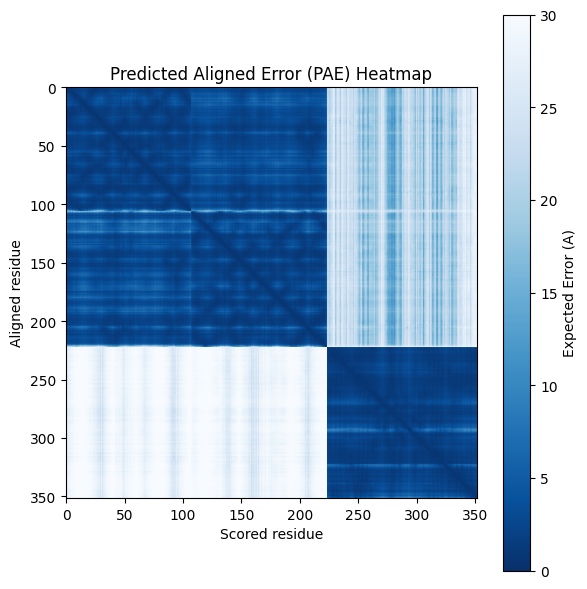

In [39]:
# Exercise 1 - PAE heatmap.
# The full-data JSON holds the PAE matrix (look for a key containing 'pae').
# Use find_confidence()'s walk pattern, or inspect the keys directly.

# YOUR CODE HERE
import json
import matplotlib.pyplot as plt
import numpy as np
import glob

json_files = glob.glob("**/*.json", recursive=True)
pae_data = None

for jf in json_files:
    with open(jf) as f:
        content = json.load(f)
        # Look for pae matrix in content
        def search_pae(obj):
            if isinstance(obj, dict):
                for k, v in obj.items():
                    if "pae" in k.lower() and isinstance(v, list):
                        return v
                    res = search_pae(v)
                    if res is not None: return res
            elif isinstance(obj, list):
                for item in obj:
                    res = search_pae(item)
                    if res is not None: return res
            return None
        pae_matrix = search_pae(content)
        if pae_matrix is not None:
            pae_data = np.array(pae_matrix)
            break

if pae_data is not None and pae_data.ndim == 2:
    plt.figure(figsize=(6, 6))
    plt.imshow(pae_data, cmap="Blues_r", vmin=0, vmax=30)
    plt.colorbar(label="Expected Error (A)")
    plt.title("Predicted Aligned Error (PAE) Heatmap")
    plt.xlabel("Scored residue")
    plt.ylabel("Aligned residue")
    plt.tight_layout()
    plt.show()
else:
    print("PAE matrix not found in JSON files.")

In [40]:
# Exercise 2 - did the server's ranking pick the most accurate model?
# Server model files are usually numbered by rank (model_0 = top ranked).

# YOUR CODE HERE
if 'my_results' in globals() and len(my_results) > 0:
    # Assuming model filenames contain ranks (e.g., model_0)
    best_model_by_dockq = my_results.loc[my_results["DockQ"].idxmax()]["model"]
    top_ranked_model = my_results.iloc[0]["model"]

    print(f"Top server-ranked model: {top_ranked_model}")
    print(f"Best model by actual DockQ: {best_model_by_dockq}")
    if top_ranked_model == best_model_by_dockq:
        print("Ranking succeeded: The top-ranked model was the most accurate.")
    else:
        print("Ranking failed: A lower-ranked model was actually more accurate.")
else:
    print("Run scoring first to check server ranking.")


Run scoring first to check server ranking.


---

### Where we go next

You have now predicted an antibody, an antigen, and the two together — and measured how far each can be
trusted. **That closes the structure-prediction arc.** Weeks 8 onward ask different questions about
antibodies: not *what shape is it* but *will it survive being made into a drug*.

| Week | Relationship to today |
|---|---|
| **7** | Every structure so far has been a single frozen frame. Next week it moves — and the CDR-H3 that predictors struggle with is the part that moves most. |
| **8** | Developability: a perfect binder that aggregates is worthless. No structure prediction required. |
| **11** | Redesigning a paratope. You will need an honest view of how well you know where that paratope is. |
| **13** | Data leakage, benchmark optimism, and confusing a confidence metric with an affinity — today supplied the examples. |

Before week 7: finish exercises 1 and 2, upload your results to the class sheet, and commit.